In [48]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch
import pyarrow
import seaborn as sns
from pathlib import Path

In [49]:
BASE_DIR = Path.cwd().resolve().parent
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"

In [50]:
ruta_mapa = BASE_DIR / "data"/"processed"/"LIM_DEPARTAMENTAL_PERU_MIN.json"
ruta_provinvial = BASE_DIR / "data"/"processed"/"LIM_PROVINCIAL_PERU.json"
peru = gpd.read_file(ruta_mapa)
provincias_peru = gpd.read_file(ruta_provinvial)

In [51]:
df_cap300ab = pd.read_parquet(RAW_DIR / "08_CAP300AB.parquet")
df_caratula = pd.read_parquet(RAW_DIR / "CARATULA.parquet")

In [52]:
df_ancash = df_cap300ab.loc[df_cap300ab["NOMBREDD"] == "ANCASH"]
df_lalibertad = df_cap300ab.loc[df_cap300ab["NOMBREDD"] == "LA LIBERTAD"]

In [53]:
caratula_ancash = df_caratula.loc[df_caratula["NOMBREDD"] == "ANCASH"]
caratula_lalibertad = df_caratula.loc[df_caratula["NOMBREDD"] == "LA LIBERTAD"]

In [54]:
map_ancash = peru.loc[peru["NOMBDEP"] == "ANCASH"]
map_prov_ancash = provincias_peru.loc[provincias_peru["NOMBDEP"]== "ANCASH"]
map_lalibertad = peru.loc[peru["NOMBDEP"] == "LA LIBERTAD"]
map_prov_lalibertad = provincias_peru.loc[provincias_peru["NOMBDEP"]== "LA LIBERTAD"]

In [55]:
puntos_ancash = gpd.GeoDataFrame(
    caratula_ancash,
    geometry = gpd.points_from_xy(
        caratula_ancash["LONGITUD"],
        caratula_ancash["LATITUD"]
    ),
    crs = "EPSG:4326"
).copy()

In [56]:
puntos_lalibertad = gpd.GeoDataFrame(
    caratula_lalibertad,
    geometry = gpd.points_from_xy(
        caratula_lalibertad["LONGITUD"],
        caratula_lalibertad["LATITUD"]
    ),
    crs = "EPSG:4326"
).copy()

## ANCASH

### Uso de Análisis de Suelos en productoras independientes

In [57]:
df_ancash["P301A_1"].value_counts()

P301A_1
2    3047
1      38
Name: count, dtype: int64

In [58]:
df_ancash["P301A_1"] = df_ancash["P301A_1"].astype("string")

In [59]:
df_ancash["P301A_1"].value_counts()

P301A_1
2    3047
1      38
Name: count, dtype: int64[pyarrow]

In [60]:
mapeo_P301A_1 = {
    "1" : "SI",
    "2": "NO"
}

In [61]:
df_ancash["P301A_1"] = df_ancash["P301A_1"].replace(mapeo_P301A_1)

In [62]:
P301A_1 = df_ancash[["P301A_1", "NSEGM","UA"]]

In [63]:
puntos_ancash_P301A_1 = pd.merge(
    puntos_ancash,
    P301A_1,
    on = ["NSEGM", "UA"],
    how = "outer"
)

In [64]:
puntos_ancash_P301A_1["P301A_1"].value_counts(dropna=False)

P301A_1
NO      3047
<NA>      88
SI        38
Name: count, dtype: int64[pyarrow]

In [65]:
condiciones_P301A_1 = [
    (puntos_ancash_P301A_1["P301A_1"] == "SI").fillna(False),
    (puntos_ancash_P301A_1["P301A_1"] == "NO").fillna(False)
]

colores_P301A_1 = ["green", "salmon"]

In [66]:
puntos_ancash_P301A_1["color_P301A_1"] = np.select(
    condiciones_P301A_1,
    colores_P301A_1,
    default = "silver"
)

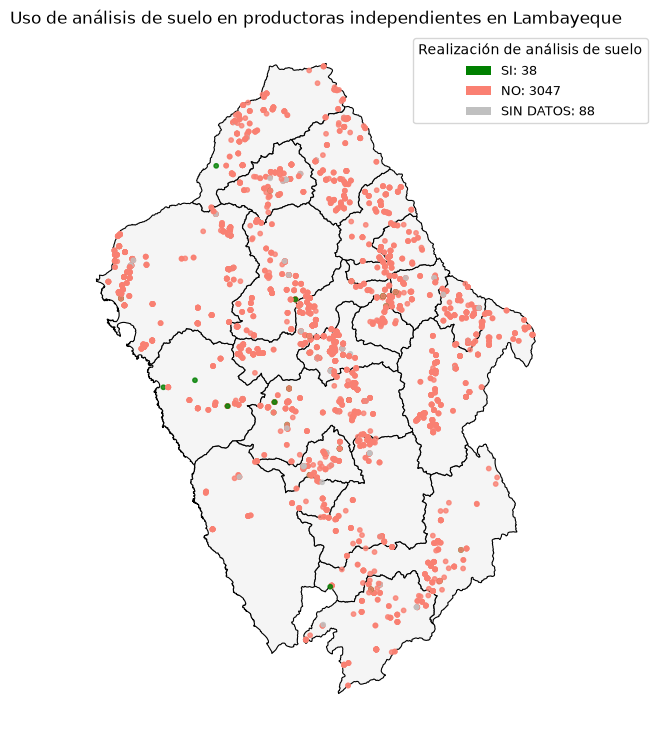

In [67]:
fig, ax = plt.subplots(figsize=(9, 9))

map_prov_ancash.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8
)

puntos_ancash_P301A_1.plot(
    ax=ax,
    color=puntos_ancash_P301A_1["color_P301A_1"],
    markersize=10,
    alpha=0.8
)

# Leyenda
leyenda = [
    Patch(facecolor="green", label=f"SI: {puntos_ancash_P301A_1["color_P301A_1"].value_counts(dropna=False)["green"]}"),
    Patch(facecolor="salmon", label=f"NO: {puntos_ancash_P301A_1["color_P301A_1"].value_counts(dropna=False)["salmon"]}"),
    Patch(facecolor="silver", label=f"SIN DATOS: {puntos_ancash_P301A_1["color_P301A_1"].value_counts(dropna=False)["silver"]}")
]

ax.legend(
    handles=leyenda,
    title="Realización de análisis de suelo",
    loc="upper right",
    bbox_to_anchor=(1.2, 1),
    fontsize=9,
    title_fontsize=10,
)

ax.set_title("Uso de análisis de suelo en productoras independientes en Lambayeque")
ax.set_axis_off()

#plt.tight_layout()
plt.show()

### Uso de abonos y fertilizantes en productoras independientes

In [68]:
# USO DE ABONO
df_ancash["P301A_13"].value_counts(dropna=False)

P301A_13
1    2273
2     812
Name: count, dtype: int64

In [69]:
df_ancash["P301A_13"] = df_ancash["P301A_13"].astype("string")

mapeo_P301A_13 = {
    "1": "SI",
    "2": "NO"
}

df_ancash["P301A_13"] = df_ancash["P301A_13"].replace(mapeo_P301A_13)

df_ancash["P301A_13"].value_counts(dropna=False)

P301A_13
SI    2273
NO     812
Name: count, dtype: int64[pyarrow]

In [70]:
df_ancash["P301A_14"].value_counts(dropna=False)

P301A_14
1    2128
2     957
Name: count, dtype: int64

In [71]:
df_ancash["P301A_14"] = df_ancash["P301A_14"].astype("string")

mapeo_P301A_14 = {
    "1": "SI",
    "2": "NO"
}

df_ancash["P301A_14"] = df_ancash["P301A_14"].replace(mapeo_P301A_14)

df_ancash["P301A_14"].value_counts(dropna=False)

P301A_14
SI    2128
NO     957
Name: count, dtype: int64[pyarrow]

In [72]:
tabla_abono_fert = df_ancash[["P301A_13", "P301A_14", "NSEGM", "UA"]]
tabla_abono_fert.head(3)

,P301A_13,P301A_14,NSEGM,UA
32278,SI,SI,18085,1
32279,SI,SI,18085,2
32280,SI,SI,18085,3


In [73]:
abono_fert_merge = pd.merge(
    puntos_ancash,
    tabla_abono_fert,
    on = ["NSEGM", "UA"],
    how = "outer"
)
abono_fert_merge.head(3)

,ANIO,CCDD,NOMBREDD,CCPP,NOMBREPV,CCDI,NOMBREDI,NSEGM,ID_PROD,UA,RESFIN,REGION,ESTRATO,FACTOR_PRODUCTOR,CODIGO,LATITUD,LONGITUD,geometry,P301A_13,P301A_14
0,2024,2.0,ANCASH,20.0,YUNGAY,8.0,YANAMA,18085,1,1,1,2,22042002.0,73.70928,1,-9.034495,-77.464259,POINT (-77.46426 -9.03449),SI,SI
1,2024,2.0,ANCASH,20.0,YUNGAY,8.0,YANAMA,18085,2,2,1,2,22042002.0,44.63348,1,-9.034495,-77.464259,POINT (-77.46426 -9.03449),SI,SI
2,2024,2.0,ANCASH,20.0,YUNGAY,8.0,YANAMA,18085,3,3,1,2,22042002.0,14.26842,1,-9.034495,-77.464259,POINT (-77.46426 -9.03449),SI,SI


In [74]:
condiciones_abono_fert = [
    ((abono_fert_merge["P301A_13"] == "SI") & (abono_fert_merge["P301A_14"] == "NO")).fillna(False),
    ((abono_fert_merge["P301A_13"] == "NO") & (abono_fert_merge["P301A_14"] == "SI")).fillna(False),
    ((abono_fert_merge["P301A_13"] == "SI") & (abono_fert_merge["P301A_14"] == "SI")).fillna(False),
    ((abono_fert_merge["P301A_13"] == "NO") & (abono_fert_merge["P301A_14"] == "NO")).fillna(False)
]

categorias_abono_fert = ["ABONO", "FERTILIZANTE", "AMBOS", "NINGUNO"]

abono_fert_merge["ABONO_Y_FERT"] = np.select(
    condiciones_abono_fert,
    categorias_abono_fert,
    default = "N.A"
)

In [75]:
condiciones_abono_fert_color = [
    (abono_fert_merge["ABONO_Y_FERT"] == "ABONO").fillna(False),
    (abono_fert_merge["ABONO_Y_FERT"] == "FERTILIZANTE").fillna(False),
    (abono_fert_merge["ABONO_Y_FERT"] == "AMBOS").fillna(False),
    (abono_fert_merge["ABONO_Y_FERT"] == "NINGUNO").fillna(False)
]

colores_abono_fert = ["lightgreen", "skyblue", "orange", "brown"]

abono_fert_merge["color"] = np.select(
    condiciones_abono_fert,
    colores_abono_fert,
    default = "black"
)

In [76]:
abono_fert_merge["ABONO_Y_FERT"].value_counts(dropna=False)

ABONO_Y_FERT
AMBOS           1699
ABONO            574
FERTILIZANTE     429
NINGUNO          383
N.A               88
Name: count, dtype: int64

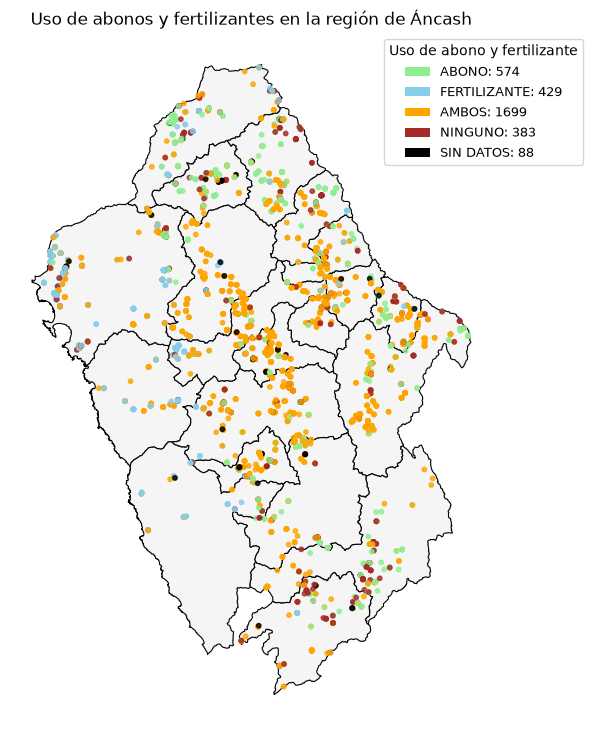

In [77]:
fig, ax = plt.subplots(figsize=(9, 9))

map_prov_ancash.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8
)

abono_fert_merge.plot(
    ax=ax,
    color=abono_fert_merge["color"],
    markersize=10,
    alpha=0.8
)

# Leyenda
leyenda = [
    Patch(facecolor="lightgreen", label=f"ABONO: {abono_fert_merge["ABONO_Y_FERT"].value_counts(dropna=False)["ABONO"]}"),
    Patch(facecolor="skyblue", label=f"FERTILIZANTE: {abono_fert_merge["ABONO_Y_FERT"].value_counts(dropna=False)["FERTILIZANTE"]}"),
    Patch(facecolor="orange", label=f"AMBOS: {abono_fert_merge["ABONO_Y_FERT"].value_counts(dropna=False)["AMBOS"]}"),
    Patch(facecolor="brown", label=f"NINGUNO: {abono_fert_merge["ABONO_Y_FERT"].value_counts(dropna=False)["NINGUNO"]}"),
    Patch(facecolor="black", label=f"SIN DATOS: {abono_fert_merge["ABONO_Y_FERT"].value_counts(dropna=False)["N.A"]}")
]

ax.legend(
    handles=leyenda,
    title="Uso de abono y fertilizante",
    loc="upper right",
    fontsize=9,
    title_fontsize=10,
    bbox_to_anchor = (1.2,1)
)

ax.set_title("Uso de abonos y fertilizantes en la región de Áncash")
ax.set_axis_off()

plt.show()

### Equipo de protección usado para la aplicación de plaguicidas

In [78]:
equipos_proteccion = {
    "P325B_1": "Guantes",
    "P325B_2": "Mascarilla",
    "P325B_3": "Botas",
    "P325B_4": "Mameluco",
    "P325B_5": "Lentes",
    "P325B_6": "Otro",
    "P325B_7": "Ninguno",
}

columnas_equipo = list(equipos_proteccion.keys())

In [79]:
# frec_equipos_prov = (
#     df_ancash
#     .groupby("NOMBREPV")[columnas_equipo]
#     .sum()
# ).reset_index()

frec_equipos = (
    df_ancash[columnas_equipo]
    .sum()
    .sort_values(ascending=False)
    .rename(index=equipos_proteccion)
)

frer_equipos = (frec_equipos/len(df_ancash)*100).round(2)
frer_equipos

Mascarilla    29.40
Botas         21.26
Ninguno       18.22
Guantes       15.82
Mameluco       9.27
Lentes         3.27
Otro           2.66
dtype: float64

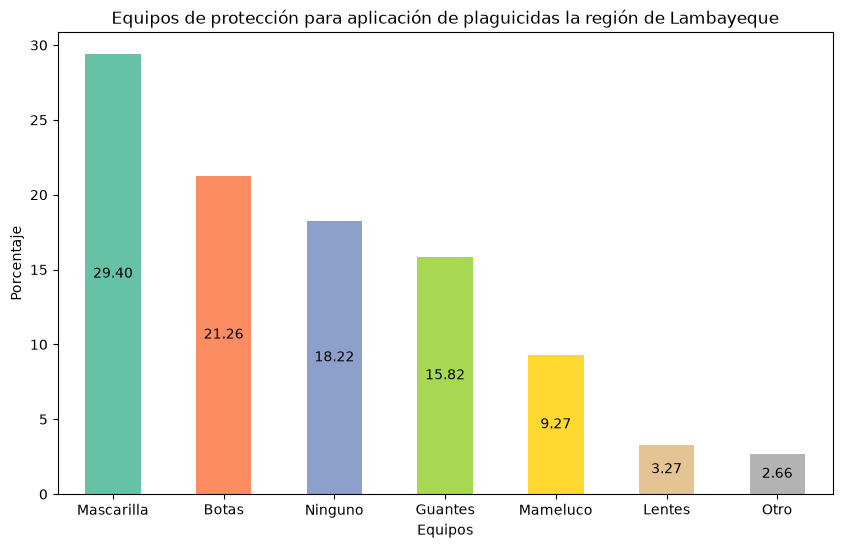

In [80]:
cmap = plt.get_cmap("Set2", len(frer_equipos))
colores = [cmap(i) for i in range(len(frer_equipos))]

gr_reg_tipo_equipo = frer_equipos.plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_tipo_equipo.set_title("Equipos de protección para aplicación de plaguicidas la región de Lambayeque")
gr_reg_tipo_equipo.set_xlabel("Equipos")
gr_reg_tipo_equipo.set_ylabel("Porcentaje")  


for container in gr_reg_tipo_equipo.containers:
    gr_reg_tipo_equipo.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 0)
plt.show()

### Manejo de envases de plaguicidas

In [81]:
manejo_envases = {
    "P325B_1": "Guantes",
    "P325B_2": "Mascarilla",
    "P325B_3": "Botas",
    "P325B_4": "Mameluco",
    "P325B_5": "Lentes",
    "P325B_6": "Otro",
    "P325B_7": "Ninguno",
}

columnas_manejo_envases = list(manejo_envases.keys())

In [82]:
frec_manejo_envases = (
    df_ancash[columnas_manejo_envases]
    .sum()
    # .sort_values(ascending=False)
    .rename(index=manejo_envases)
)

frec_manejo_envases = (frec_manejo_envases/len(df_ancash)*100).round(2)
frec_manejo_envases

Guantes       15.82
Mascarilla    29.40
Botas         21.26
Mameluco       9.27
Lentes         3.27
Otro           2.66
Ninguno       18.22
dtype: float64

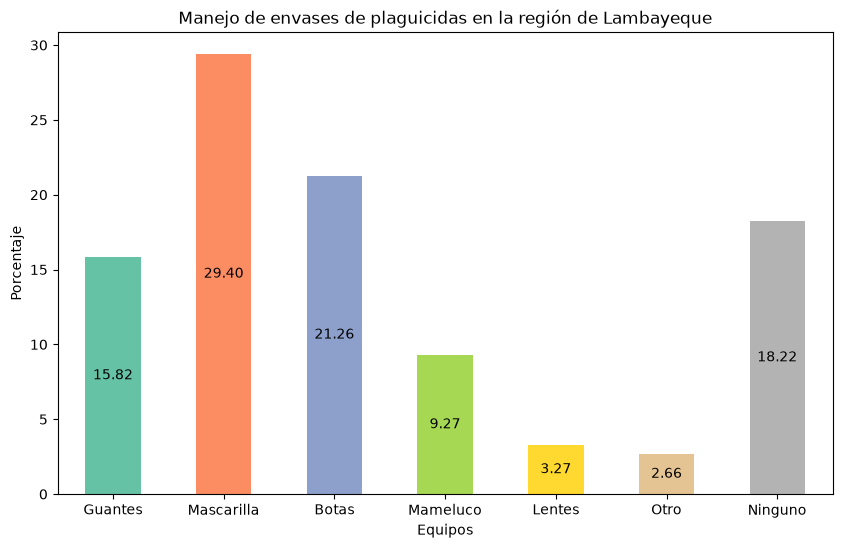

In [83]:
cmap = plt.get_cmap("Set2", len(frec_manejo_envases))
colores = [cmap(i) for i in range(len(frec_manejo_envases))]

gr_reg_manejo_envases = frec_manejo_envases.plot(
    kind = "bar",
    stacked = False,
    figsize = (10, 6),
    color = colores,
)
gr_reg_manejo_envases.set_title("Manejo de envases de plaguicidas en la región de Lambayeque")
gr_reg_manejo_envases.set_xlabel("Equipos")
gr_reg_manejo_envases.set_ylabel("Porcentaje")  


for container in gr_reg_manejo_envases.containers:
    gr_reg_manejo_envases.bar_label(
        container,
        fmt = "%.2f",
        label_type = "center",
        fontsize = 10
    )
plt.xticks(rotation = 0)
plt.show()